In [ ]:
import gc
import geopandas as gpd
import json
import numpy as np
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import os
import pandas as pd
from pathlib import Path
import scanpy as sc
from shapely.geometry import box
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, homogeneity_score, completeness_score, v_measure_score

%run functions.ipynb

In [ ]:
# Basic variables
sample = "CRC_P2"
bin_size = "002um"
cellseg_dir = "cell_seg_stardist"


# Basic paths
basedir = Path("../data/")
dir_sample = basedir / sample
dir_base_output = dir_sample / f"output/binned_outputs/square_{bin_size}"
dir_custom_binning = dir_sample / "01_preprocessing" / cellseg_dir / bin_size /  "custom_binning"

# SpaGCN

In [ ]:
# Paths
dir_spagcn = dir_sample / "02_baselines/spagcn"

# Files
spagcn_results = sc.read_h5ad(dir_spagcn / "results" / sample / "results_cluster_7.h5ad")
filtered_custom_bins = sc.read_h5ad(dir_custom_binning / "filtered_custom_bins.h5ad")
ground_truth = pd.read_csv((dir_sample / "ground_truth/2um_squares_annotation.csv"), delimiter='\t', header=None, names=['barcode', 'ground_truth'])

# .obs dataframes
spagcn_obs = spagcn_results.obs.copy()
bins_obs = filtered_custom_bins.obs.copy()

# Join bins with nuclei - store cluster info bin wise to match with ground truth
merged_obs = bins_obs.join(spagcn_obs, on="id", how="inner")

merged_obs = merged_obs.drop(columns=["in_tissue", "array_row", "array_col", "index_x", 
                                      "index_y", "is_within_polygon", "is_not_in_an_polygon_overlap", 
                                      "Slide_ID", "x1", "x_array", "y_array", "x_pixel", "y_pixel"]) # readability
# Join with ground truth
merged_obs = merged_obs.join(ground_truth.set_index("barcode"), how="inner")
merged_obs

#del spagcn_results, filtered_custom_bins, spagcn_obs, bins_obs # free up space
#gc.collect()

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


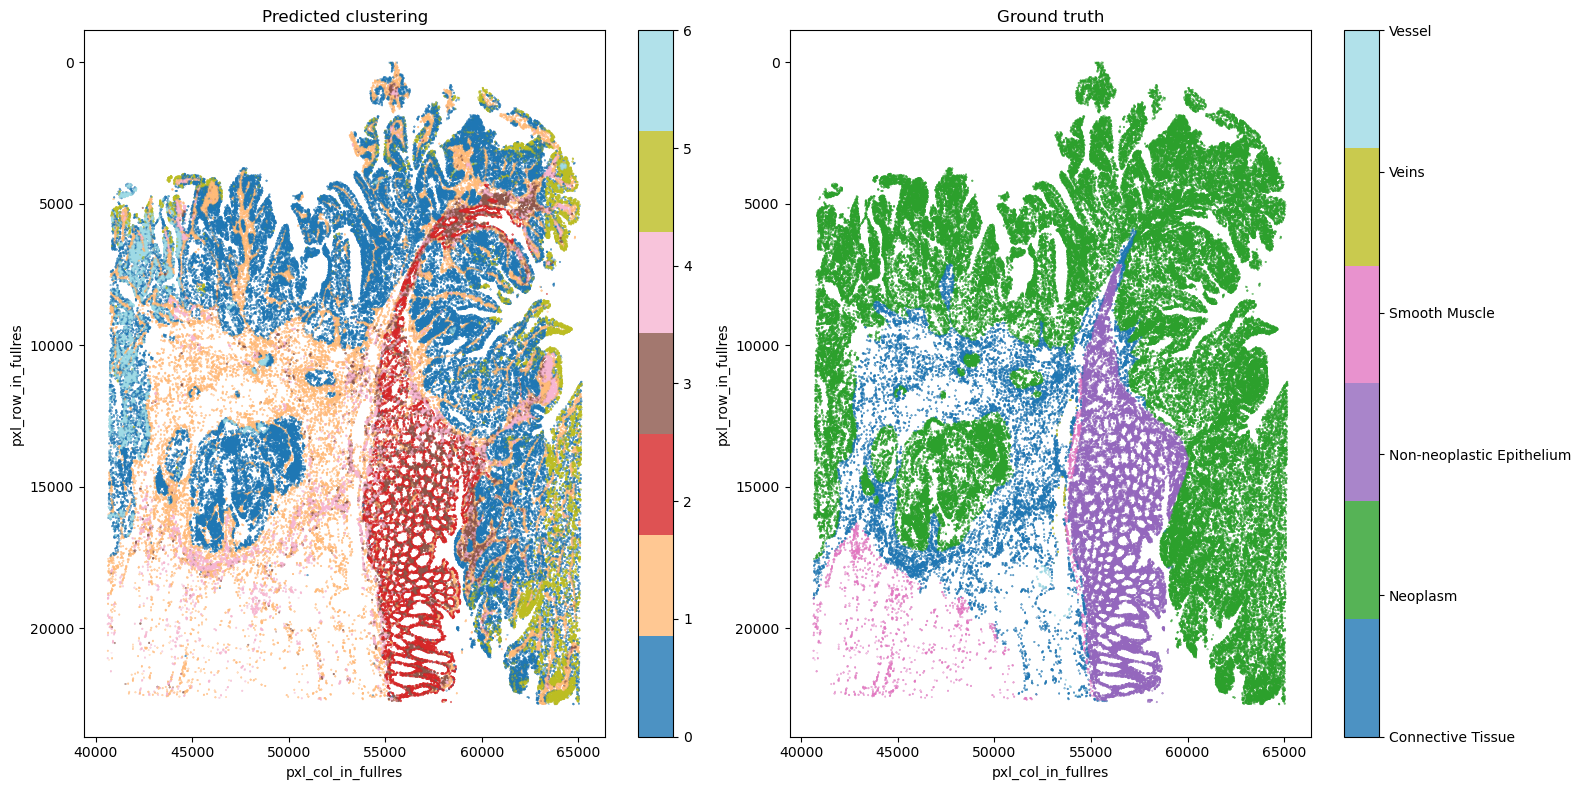

In [24]:
plot_bin_clusters_side_by_side(merged_obs, 'pxl_col_in_fullres', 'pxl_row_in_fullres', "pred", "truth")

In [ ]:
get_eval_scores(merged_obs, "pred", "ground_truth")

Adjusted Rand Index: 0.276
Normalized Mutual Info: 0.306
Homogeneity: 0.471
Completeness: 0.227
V-Measure: 0.306


In [ ]:
get_eval_scores(merged_obs, "refined_pred", "ground_truth")

Adjusted Rand Index: 0.281
Normalized Mutual Info: 0.315
Homogeneity: 0.485
Completeness: 0.233
V-Measure: 0.315
